# Module 3: Estimation, Forecasting and Discrete Models, Tested on Real Data

*By Héctor Ornelas*

Modules 1 and 2 described returns and assumed that the parameters were known. This module turns the
problem around: with real data, how well can we estimate those parameters, how do we choose a model,
and how good are its forecasts? It closes with two discrete models used everywhere in practice, the
binomial tree and the gambler's ruin. As before, I take the twelve topics of the course in the same
order and test each one with real series.

The rules are the same as in Module 1: same topics as the course, real data from a Mexican point of
view, and every formula written by hand.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import comb, erf, exp, log, sqrt

# fix the seed so every run gives exactly the same numbers
np.random.seed(37)

# one common style for all the plots: size, a light grid, and font size
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 11})

def normal_cdf(x):
    return 0.5 * (1 + erf(x / sqrt(2)))

def acf(x, k):
    # sample autocorrelation at lag k
    x = np.asarray(x) - np.mean(x)
    return np.sum(x[k:] * x[:len(x) - k]) / np.sum(x * x)

prices = pd.read_csv("data/prices.csv", index_col=0, parse_dates=True)
prices["SPY_MXN"] = prices["SPY"] * prices["USDMXN"]

def log_ret(col):
    return np.log(prices[col].dropna()).diff().dropna()

r = log_ret("IPC")

## 1. Statistics, estimators and sampling distributions

A **statistic** is a function of the data, like the sample mean or the sample standard deviation. An
**estimator** is the same formula seen before the data arrives: since the data is random, the
estimator is a random variable with its own distribution. If the returns have a fixed volatility
$\sigma$, the textbook standard errors for $T$ years of daily data are

$$\mathrm{SE}(\hat\mu) = \frac{\sigma}{\sqrt{T}}, \qquad \mathrm{SE}(\hat\sigma) \approx \frac{\sigma}{\sqrt{2n}},$$

where $n$ is the number of days.

**Exercise 1. One estimate per year.** I treat each calendar year of the IPC as one sample, estimate
the mean and the volatility from each year, and compare the spread of those estimates with the
standard errors.

21 yearly samples of the IPC

mu_hat   : average +7.65%   spread 17.60%   (theory sigma / sqrt(1 year) = 18.45%)
sigma_hat: average 17.49%   spread 6.15%   (theory sigma / sqrt(2 x 252) = 0.82%)


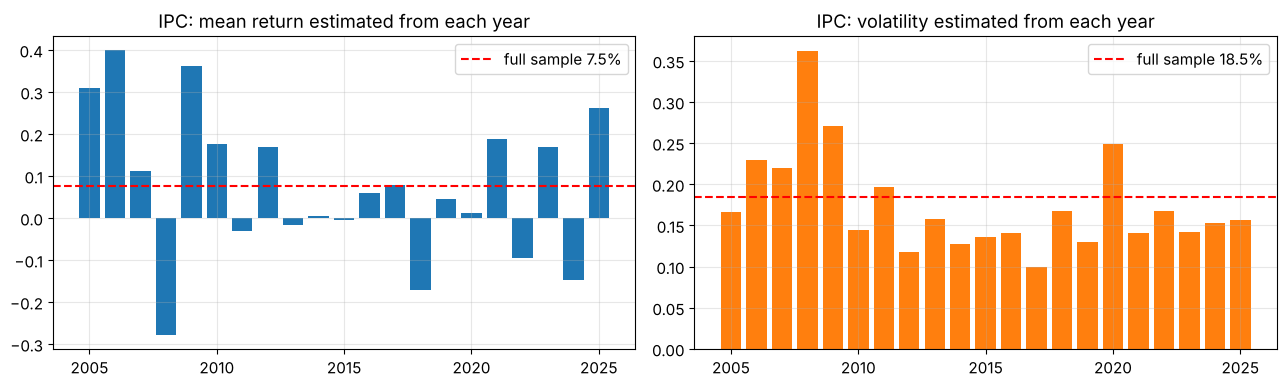

In [2]:
# each calendar year is one sample of about 252 days: estimate mu and sigma from each one
years = r.groupby(r.index.year)
mu_hat = years.mean() * 252
sig_hat = years.std() * sqrt(252)
full = years.size() > 240                      # full years only
mu_hat, sig_hat = mu_hat[full], sig_hat[full]

mu, sig = r.mean() * 252, r.std() * sqrt(252)
print(f"{len(mu_hat)} yearly samples of the IPC\n")
print(f"mu_hat   : average {mu_hat.mean():+.2%}   spread {mu_hat.std():.2%}   (theory sigma / sqrt(1 year) = {sig:.2%})")
print(f"sigma_hat: average {sig_hat.mean():.2%}   spread {sig_hat.std():.2%}   (theory sigma / sqrt(2 x 252) = {sig / sqrt(2 * 252):.2%})")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(mu_hat.index, mu_hat.values); ax[0].axhline(mu, color="red", ls="--", label=f"full sample {mu:.1%}")
ax[0].set_title("IPC: mean return estimated from each year"); ax[0].legend()
ax[1].bar(sig_hat.index, sig_hat.values, color="tab:orange"); ax[1].axhline(sig, color="red", ls="--", label=f"full sample {sig:.1%}")
ax[1].set_title("IPC: volatility estimated from each year"); ax[1].legend()
plt.tight_layout(); plt.show()

The yearly mean estimates go from $-28\%$ to $+40\%$, and their spread (17.6%) is very close to the
theory (18.5%), so one year of data says almost nothing about the expected return. The volatility
estimates are much more stable, but their spread is 6.15% when the theory says 0.82%. The formula is
not wrong, it assumes that $\sigma$ is the same every year, and the plot on the right shows that it is
not: the volatility was 36% in 2008 and 10% in 2017. So the spread of the volatility estimates comes
mostly from real changes in risk, not from estimation error.

## 2. Bias: why we divide by $n-1$

An estimator is **unbiased** if its average equals the true value. The sample variance computed with
$1/n$ is too small on average, because it measures the distance to the sample mean, which is fitted to
the same data and is always a bit closer to the points than the true mean. Dividing by $n-1$ corrects
this.

**Exercise 2. Measuring the bias.** To know the true variance, I treat the 21 years of IPC daily
returns as the whole population. Then I draw 200,000 samples of 10 days from it and compare the
average of both formulas with the true variance.

In [3]:
# treat the 21 years of IPC daily returns as the whole population, so the true variance is known,
# and draw many small samples of 10 days from it
pop = r.values
true_var = np.mean((pop - pop.mean())**2)
n, reps = 10, 200_000
samples = pop[np.random.randint(0, len(pop), size=(reps, n))]

v_n = samples.var(axis=1, ddof=0).mean()       # divide by n
v_n1 = samples.var(axis=1, ddof=1).mean()      # divide by n - 1
print(f"true variance   : {true_var:.3e}")
print(f"divide by n     : {v_n:.3e}   ratio {v_n / true_var:.4f}   (theory (n-1)/n = {(n - 1) / n:.4f})")
print(f"divide by n - 1 : {v_n1:.3e}   ratio {v_n1 / true_var:.4f}   (theory 1)")

true variance   : 1.351e-04
divide by n     : 1.217e-04   ratio 0.9014   (theory (n-1)/n = 0.9000)
divide by n - 1 : 1.353e-04   ratio 1.0016   (theory 1)


Dividing by $n$ gives 0.9014 of the true variance, almost exactly the predicted $(n-1)/n = 0.9$, so
with 10 days the variance is underestimated by 10%. Dividing by $n-1$ gives 1.0016, unbiased. With a
year of data the difference is only 0.4%, so this matters mostly for short windows, like a risk
estimate made with the last two weeks of data.

## 3. Why the mean return is so much harder to estimate than volatility

The standard error of the mean is $\sigma/\sqrt{T}$, where $T$ is the length of the history **in
years**, and it does not improve by measuring more often: daily data gives more numbers, but not more
information about the drift. The volatility is the opposite, since its precision improves with the
number of observations.

**Exercise 3. How many years would we need?** First I compute how many years of data are needed to
know the mean return of the IPC and the SPY in pesos within $\pm$5%, $\pm$2% and $\pm$1% (two
standard errors). Then I split the history of four series in two halves and estimate both numbers in
each half.

In [4]:
print("years of data needed to know the mean return within +/- 2 standard errors:")
for c in ["IPC", "SPY_MXN"]:
    s = log_ret(c).std() * sqrt(252)
    need = [(2 * s / e)**2 for e in [0.05, 0.02, 0.01]]
    print(f"   {c:<8} vol {s:.1%}:  +/-5% -> {need[0]:4.0f} years   +/-2% -> {need[1]:5.0f} years   +/-1% -> {need[2]:6.0f} years")

# split the history in two halves and estimate both numbers in each one
print(f"\n{'series':<9}{'mean 1st half':>14}{'mean 2nd half':>14}{'vol 1st half':>13}{'vol 2nd half':>13}")
for c in ["IPC", "SPY", "USDMXN", "GLD"]:
    x = log_ret(c)
    a, b = x.iloc[:len(x) // 2], x.iloc[len(x) // 2:]
    print(f"{c:<9}{a.mean() * 252:>14.2%}{b.mean() * 252:>14.2%}{a.std() * sqrt(252):>13.2%}{b.std() * sqrt(252):>13.2%}")

years of data needed to know the mean return within +/- 2 standard errors:
   IPC      vol 18.5%:  +/-5% ->   54 years   +/-2% ->   340 years   +/-1% ->   1362 years
   SPY_MXN  vol 18.4%:  +/-5% ->   54 years   +/-2% ->   339 years   +/-1% ->   1355 years

series    mean 1st half mean 2nd half vol 1st half vol 2nd half
IPC              11.10%         3.97%       20.64%       15.96%
SPY               7.06%        13.65%       19.99%       17.71%
USDMXN            3.76%         0.82%       11.05%       12.40%
GLD               7.98%        11.96%       19.98%       16.49%


To know the mean return of the IPC within $\pm 2\%$, I would need 340 years of data, and within
$\pm 1\%$ more than 1,300 years. The split confirms it. The mean of the IPC goes from 11.1% in the first
half to 4.0% in the second, and the mean of the SPY almost doubles, from 7.1% to 13.7%, while the
volatilities of the four series change by a few points at most. This is the most practical result of
the course for me. Every trading course I took was about predicting where the price will go, and that
is exactly the number that the data cannot estimate. The risk, on the other hand, can be measured.

## 4. Log returns and simple returns

Investment reports use **simple** returns, $R = P_t/P_{t-1} - 1$, but the math is easier with **log**
returns, $r = \ln(P_t/P_{t-1})$, because log returns add across time while simple returns multiply.
They carry the same information and are linked by $R = e^r - 1$.

**Exercise 4. Yearly returns of the IPC.** I compute the yearly returns of the IPC from 2005 to 2025
in both ways, and I check which one can be added to get the total change.

In [5]:
p = prices["IPC"].dropna()
yearly = p.groupby(p.index.year).last()
yearly = yearly[yearly.index <= 2025]
start = p.iloc[0]
level = pd.concat([pd.Series([start], index=[2004]), yearly])

simple = level.pct_change().dropna()
logr = np.log(level).diff().dropna()

print(" year    simple      log")
for y in [2008, 2009, 2020, 2023]:
    print(f" {y}  {simple[y]:+8.2%}  {logr[y]:+8.2%}")

total = level.iloc[-1] / level.iloc[0] - 1
print(f"\n2005-2025, real total change     : {total:+.1%}")
print(f"sum of the yearly simple returns : {simple.sum():+.1%}   (wrong)")
print(f"sum of the yearly log returns    : {logr.sum():+.1%}  ->  exp(sum) - 1 = {np.exp(logr.sum()) - 1:+.1%}")
print(f"\nafter a -30% year you need {1 / 0.7 - 1:+.1%} to get back to the start")

 year    simple      log
 2008   -24.23%   -27.75%
 2009   +43.52%   +36.13%
 2020    +1.21%    +1.20%
 2023   +18.41%   +16.90%

2005-2025, real total change     : +393.8%
sum of the yearly simple returns : +199.4%   (wrong)
sum of the yearly log returns    : +159.7%  ->  exp(sum) - 1 = +393.8%

after a -30% year you need +42.9% to get back to the start


For a quiet year like 2020 the two are almost equal, but for big years they are not: in 2008 the IPC
fell 24.2% in simple terms and 27.8% in log terms. The total shows why this matters. From 2005 to 2025
the IPC went up 393.8%, but adding the yearly simple returns gives 199.4%, which is completely wrong.
Adding the log returns and taking the exponential gives the right answer. The asymmetry also matters
for a person: after a year of $-30\%$, the investment needs $+42.9\%$ just to get back to where it
started.

## 5. Reading autocorrelations without fooling yourself

The sample autocorrelation is noisy. Even for independent data, each lag is approximately normal with
standard deviation $1/\sqrt{T}$, so values inside $\pm 2/\sqrt{T}$ cannot be separated from zero, and
about 1 lag in 20 will fall outside only by chance.

This band has the same problem as the variance ratio in Module 2: it assumes that the volatility never
changes. When there are calm periods and crisis periods, a few crisis days carry a lot of weight and the
band should be wider, so I also compute a robust band that allows the volatility to change.

**Exercise 5. Autocorrelations of real daily returns.** For the IPC, the SPY and the peso I compute the
autocorrelation at lags 1 to 20 and count how many lags are outside each band.

series   simple band  outside  outside, robust band   lag 1  z robust
IPC         +/-0.027  5 of 20               1 of 20  +0.057      +2.7
SPY         +/-0.027  8 of 20               3 of 20  -0.101      -3.2
USDMXN      +/-0.027  4 of 20               0 of 20  +0.010      +0.3
(about 1 lag in 20 falls outside by chance)


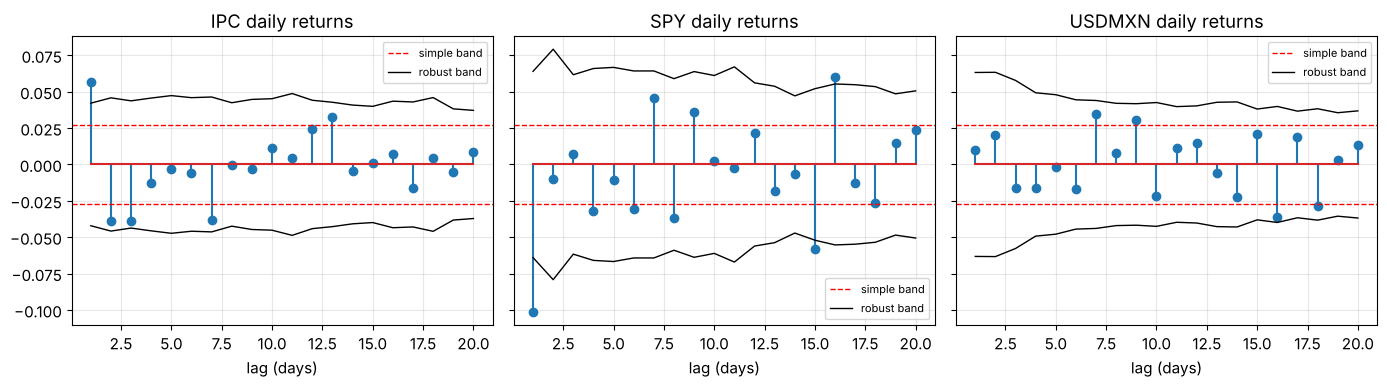

In [6]:
lags = np.arange(1, 21)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
def robust_se(x, k):
    # standard error of the lag-k autocorrelation that allows the volatility to change over time
    e = x - x.mean()
    return sqrt(np.sum(e[k:]**2 * e[:-k]**2)) / np.sum(e**2)

print(f"{'series':<8}{'simple band':>12}{'outside':>9}{'outside, robust band':>22}{'lag 1':>8}{'z robust':>10}")
for ax, c in zip(axes, ["IPC", "SPY", "USDMXN"]):
    x = log_ret(c).values
    band = 2 / sqrt(len(x))
    ac = np.array([acf(x, k) for k in lags])
    rb = np.array([2 * robust_se(x, k) for k in lags])
    out, out_r = int(np.sum(np.abs(ac) > band)), int(np.sum(np.abs(ac) > rb))
    print(f"{c:<8}{'+/-' + format(band, '.3f'):>12}{str(out) + ' of 20':>9}{str(out_r) + ' of 20':>22}{ac[0]:>+8.3f}{ac[0] / (rb[0] / 2):>+10.1f}")
    ax.stem(lags, ac)
    ax.axhline(band, color="red", ls="--", lw=1, label="simple band"); ax.axhline(-band, color="red", ls="--", lw=1)
    ax.plot(lags, rb, color="black", lw=1, label="robust band"); ax.plot(lags, -rb, color="black", lw=1)
    ax.legend(fontsize=8)
    ax.set_title(f"{c} daily returns"); ax.set_xlabel("lag (days)")
print("(about 1 lag in 20 falls outside by chance)")
plt.tight_layout(); plt.show()

With the simple band, the peso has 4 lags outside, the IPC 5 and the SPY 8, all more than the 1
expected by chance. With the robust band the picture is much cleaner: the peso has none, the IPC has 1
and the SPY has 3. Two results survive. The SPY has a lag-1 autocorrelation of $-0.10$ with a robust z of
$-3.2$, so it really tends to reverse a little the next day. This does not contradict Module 2: the
reversal is real for one day, but it does not add up to enough over a month to make the variance ratio
significant. The IPC has a lag-1 autocorrelation of 0.057 with a robust z of 2.7, which is real but very
small, since it means that yesterday's return explains about 0.3% of the variance of today's return. So
the band is a minimum test: a lag can be outside it and still be too small to use.

## 6. Choosing a model: AR or MA?

The autocorrelation function is the main tool to choose a model family:

- an **MA($q$)** has $\rho_k = 0$ for $k > q$, so its autocorrelation **cuts off**;
- an **AR($p$)** has non-zero $\rho_k$ at every lag, so its autocorrelation **tails off**.

**Exercise 6. Two real series.** I compute the autocorrelation of two monthly series of the IPC: the
log of its volatility and its return.

 lag   log vol   monthly return
   1    +0.593      +0.022
   2    +0.410      -0.008
   3    +0.369      +0.095
   4    +0.258      +0.104
   5    +0.238      +0.011
   6    +0.202      -0.121
   7    +0.200      +0.025
   8    +0.224      +0.006
   9    +0.220      -0.047
  10    +0.197      -0.064
band +/- 0.124


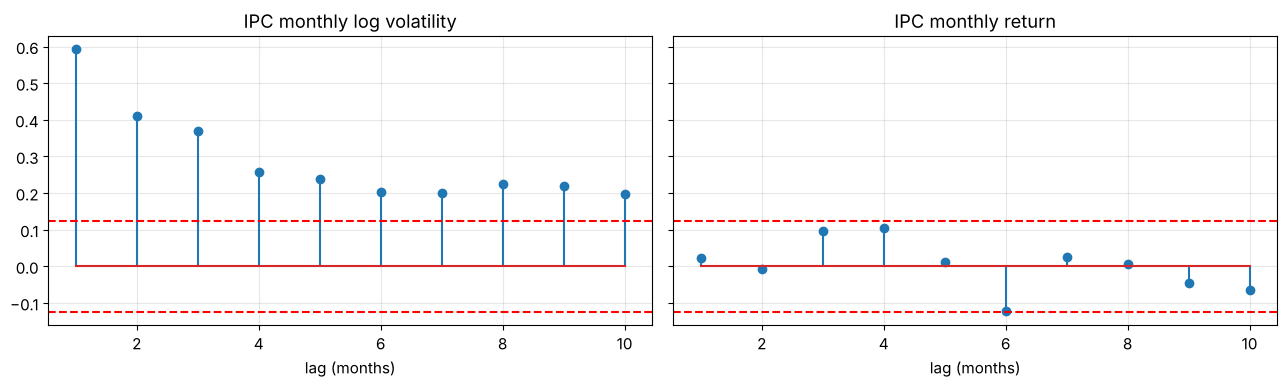

In [7]:
# two real series: the monthly log volatility of the IPC, and the monthly log return of the IPC
vol = r.groupby(r.index.to_period("M")).std() * sqrt(252)
n_days = r.groupby(r.index.to_period("M")).size()
log_vol = np.log(vol[n_days >= 15].values)
monthly_ret = r.groupby(r.index.to_period("M")).sum()[n_days >= 15].values

lags = list(range(1, 11))
band = 2 / sqrt(len(log_vol))
a_vol = [acf(log_vol, k) for k in lags]
a_ret = [acf(monthly_ret, k) for k in lags]
print(" lag   log vol   monthly return")
for k, a, b in zip(lags, a_vol, a_ret):
    print(f"  {k:2d}    {a:+.3f}      {b:+.3f}")
print(f"band +/- {band:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a, vals, title in [(ax[0], a_vol, "IPC monthly log volatility"), (ax[1], a_ret, "IPC monthly return")]:
    a.stem(lags, vals); a.axhline(band, color="red", ls="--"); a.axhline(-band, color="red", ls="--")
    a.set_title(title); a.set_xlabel("lag (months)")
plt.tight_layout(); plt.show()

The two series look very different. The log volatility starts at 0.59 and goes down slowly, and it is
still at 0.20 after 10 months, well outside the band of $\pm 0.12$. This is the pattern of an AR model.
The monthly return has no lag outside the band, so it does not need an AR or an MA model at all: it is
close to white noise. In practice, this means that the IPC's risk can be modeled and forecast, and its
direction cannot.

## 7. Forecasting: conditional expectation

A forecast is the expected value of the future given what we know today. For an AR(1) in deviations
from its long-run mean $m$, this gives

$$\mathbb{E}[v_{t+h} \mid v_t] = m + \phi^h (v_t - m),$$

so the forecast goes back to the long-run mean at a speed set by $\phi$.

**Exercise 7. Forecasting volatility after October 2008.** I fit an AR(1) to the monthly log volatility
of the IPC, as in Module 2, and I forecast the next 12 months from October 2008, the most volatile
month in the data. Then I compare with what really happened.

phi = 0.593   long-run volatility = 15.0%

 months ahead   month      forecast   actual
       1       Nov 2008     38.7%     52.5%
       2       Dec 2008     26.3%     34.4%
       3       Jan 2009     21.0%     35.4%
       4       Feb 2009     18.3%     27.1%
       5       Mar 2009     16.9%     43.6%
       6       Apr 2009     16.1%     35.7%
       7       May 2009     15.7%     28.8%
       8       Jun 2009     15.4%     25.3%
       9       Jul 2009     15.3%     21.9%
      10       Aug 2009     15.2%     18.8%
      11       Sep 2009     15.1%     17.9%
      12       Oct 2009     15.1%     22.3%


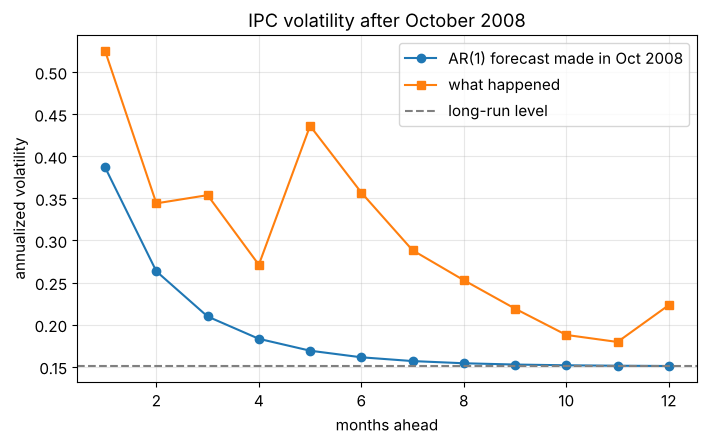

In [8]:
# AR(1) on the monthly log volatility, fitted by hand as in Module 2
v = pd.Series(log_vol, index=vol[n_days >= 15].index)
y, z = v.values[1:], v.values[:-1]
phi = np.sum((z - z.mean()) * (y - y.mean())) / np.sum((z - z.mean())**2)
m = (y.mean() - phi * z.mean()) / (1 - phi)     # long-run mean of the log volatility, c / (1 - phi)
print(f"phi = {phi:.3f}   long-run volatility = {np.exp(m):.1%}\n")

# forecast made at the end of October 2008, the most volatile month, for the next 12 months
t0 = v.index.get_loc(pd.Period("2008-10", "M"))
h = np.arange(1, 13)
fc = np.exp(m + phi**h * (v.iloc[t0] - m))
actual = np.exp(v.iloc[t0 + 1:t0 + 13].values)
print(" months ahead   month      forecast   actual")
for k in h:
    print(f"      {k:>2}       {v.index[t0 + k].strftime('%b %Y')}    {fc[k - 1]:6.1%}    {actual[k - 1]:6.1%}")

plt.plot(h, fc, "o-", label="AR(1) forecast made in Oct 2008")
plt.plot(h, actual, "s-", label="what happened")
plt.axhline(np.exp(m), color="gray", ls="--", label="long-run level")
plt.title("IPC volatility after October 2008")
plt.xlabel("months ahead"); plt.ylabel("annualized volatility"); plt.legend(); plt.show()

The forecast says that the volatility should fall from 74% to 38.7% in one month and be almost back to
normal (16.1%) after six months. What really happened is that it stayed between 27% and 53% during
those six months, and it was still 22.3% one year later, in October 2009. The direction of the forecast is right, but
the model is much too fast, which is the same limit found in Module 2. A risk manager who trusted this
forecast in November 2008 would have reduced protection too early.

## 8. Comparing forecasts: mean squared forecast error

To compare forecasts we use the **mean squared forecast error** (MSFE), the average of the squared
difference between what happened and what was predicted. To make the comparison fair, the model must
be fitted only with data that was available before each forecast.

**Exercise 8. Three forecasts of next month's volatility.** I fit the AR(1) with 2005–2015 only, and
then I forecast each month of 2016–2026 one month ahead. I compare it with the "naive" forecast (next
month equals this month) and with the long-run mean.

In [9]:
# fit on 2005-2015, then forecast every month of 2016-2026 one month ahead, without refitting
train, test = v[:"2015-12"], v["2016-01":]
yt, zt = train.values[1:], train.values[:-1]
phi_t = np.sum((zt - zt.mean()) * (yt - yt.mean())) / np.sum((zt - zt.mean())**2)
m_t = (yt.mean() - phi_t * zt.mean()) / (1 - phi_t)

prev = v.shift(1)["2016-01":].values          # last observed month before each test month
actual = test.values
forecasts = {
    "AR(1) model":        m_t + phi_t * (prev - m_t),
    "naive (last month)": prev,
    "long-run mean":      np.full(len(actual), m_t),
}
print(f"trained on {len(train)} months (phi = {phi_t:.3f}), tested on {len(test)} months\n")
print(f"{'method':<22}{'MSFE':>8}")
for name, f in forecasts.items():
    print(f"{name:<22}{np.mean((actual - f)**2):>8.4f}")

trained on 132 months (phi = 0.665), tested on 129 months

method                    MSFE
AR(1) model             0.0998
naive (last month)      0.1282
long-run mean           0.1289


The AR(1) wins, with an MSFE of 0.0998 against 0.1282 for the naive forecast and 0.1289 for the
long-run mean, so it reduces the error by around 22%. Both simple forecasts fail in opposite ways: the
naive one keeps too much of the last month, and the long-run mean ignores it completely. The AR(1)
keeps a part of it, and that is the right idea, even if Section 7 showed that the part it keeps
disappears too fast after a big crisis.

## 9. The binomial tree

A **binomial tree** is a random walk where, at each step, the price is multiplied by $u$ with
probability $p$ or by $d$ with probability $1-p$. After $n$ steps the number of up moves is
$\text{Binomial}(n, p)$, the same distribution from Module 1.

**Exercise 9. A tree for the dollar.** I build a two-step tree for USD/MXN, with steps of six months,
moves of one standard deviation, and equal probabilities. Then I compute the expected payoff of a call
and a put with a strike of 20 pesos per dollar. A call pays if the dollar ends above 20, so for a
Mexican it works like insurance against the peso losing value.

In [10]:
S0 = prices["USDMXN"].dropna().iloc[-1]
fx = log_ret("USDMXN")
sigma = fx.std() * sqrt(252)

# two steps of six months, with up and down moves of one sigma and equal probabilities
dt = 0.5
u, d, p = exp(sigma * sqrt(dt)), exp(-sigma * sqrt(dt)), 0.5
K = 20.0
print(f"USD/MXN today {S0:.2f}, volatility {sigma:.1%}, u = {u:.4f}, d = {d:.4f}\n")
print(" ups   USD/MXN   probability   call payoff   put payoff")
E_S = E_call = E_put = 0.0
for k in range(3):
    S = S0 * u**k * d**(2 - k)
    prob = comb(2, k) * p**k * (1 - p)**(2 - k)
    call, put = max(S - K, 0), max(K - S, 0)
    E_S += prob * S; E_call += prob * call; E_put += prob * put
    print(f"  {k}     {S:6.2f}      {prob:.2f}         {call:5.2f}         {put:5.2f}")
print(f"\nE[S_T] = {E_S:.4f}   E[call] = {E_call:.4f}   E[put] = {E_put:.4f}")
print(f"E[call] - E[put] = {E_call - E_put:.4f}   E[S_T] - K = {E_S - K:.4f}")

USD/MXN today 18.40, volatility 11.7%, u = 1.0866, d = 0.9203

 ups   USD/MXN   probability   call payoff   put payoff
  0      15.58      0.25          0.00          4.42
  1      18.40      0.50          0.00          1.60
  2      21.72      0.25          1.72          0.00

E[S_T] = 18.5262   E[call] = 0.4308   E[put] = 1.9047
E[call] - E[put] = -1.4738   E[S_T] - K = -1.4738


The three final values are 15.58, 18.40 and 21.72 pesos per dollar, and the middle one has probability
0.50 because two paths lead to it. The call only pays in the top node, with an expected payoff of 0.43
pesos per dollar, and the put has 1.90. The difference between the two is exactly $\mathbb{E}[S_T] - K
= -1.47$, which is **put-call parity** with a zero interest rate. These are expected payoffs with the
probabilities of the tree, not prices. Pricing an option needs a different probability and an interest
rate, which is where Module 4 goes.

## 10. Calibrating the tree to real data

A tree is only useful if its $u$, $d$ and $p$ match the drift and the volatility of the real series.
The Cox-Ross-Rubinstein choice does this:

$$u = e^{\sigma\sqrt{\Delta t}}, \qquad d = 1/u, \qquad
p = \tfrac12 + \tfrac12\frac{\mu}{\sigma}\sqrt{\Delta t}.$$

**Exercise 10. The dollar in one year.** I calibrate a 252-step tree to the drift and volatility of
USD/MXN, check the moments of each step, and compute the probability that the dollar ends above 20
pesos in one year. I compare the tree with the lognormal formula and with the history.

p = 0.5061   per-step mean 0.000091 (target 0.000091)   per-step var 0.000055 (target 0.000055)

P(USD/MXN > 20 in one year):  tree 30.9%   lognormal 30.3%
share of past 1-year windows with a move at least that big: 26.7%
independent years behind that share: about 20   standard error of a share with 20 years: 10.3%


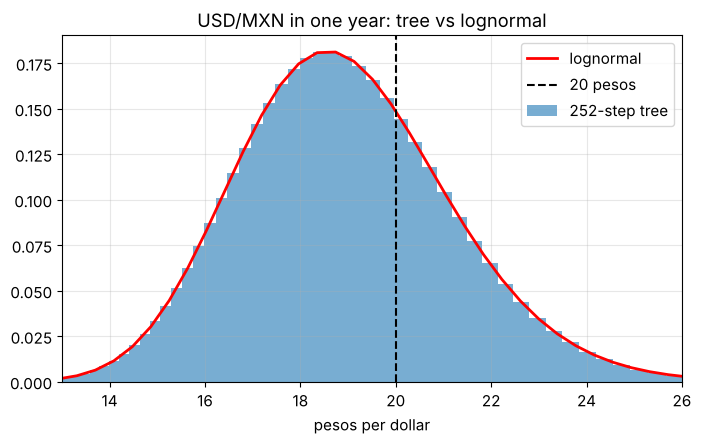

In [11]:
mu = fx.mean() * 252
N = 252
dt = 1 / N
u_c = exp(sigma * sqrt(dt)); d_c = 1 / u_c
p_c = 0.5 + 0.5 * (mu / sigma) * sqrt(dt)
r_up, r_dn = log(u_c), log(d_c)
step_mean = p_c * r_up + (1 - p_c) * r_dn
step_var = p_c * r_up**2 + (1 - p_c) * r_dn**2 - step_mean**2
print(f"p = {p_c:.4f}   per-step mean {step_mean:.6f} (target {mu * dt:.6f})   per-step var {step_var:.6f} (target {sigma**2 * dt:.6f})")

# probability that the dollar ends above 20 pesos in one year
k = np.arange(N + 1)
ST = S0 * u_c**k * d_c**(N - k)
log_pk = np.array([log(comb(N, i)) for i in k]) + k * log(p_c) + (N - k) * log(1 - p_c)
pk = np.exp(log_pk)
z = (log(20 / S0) - mu) / sigma
moves = np.log(prices["USDMXN"].dropna()).diff(252).dropna()
print(f"\nP(USD/MXN > 20 in one year):  tree {pk[ST > 20].sum():.1%}   lognormal {1 - normal_cdf(z):.1%}")
share = np.mean(moves > log(20 / S0))
n_ind = len(moves) // 252                       # the windows overlap: about one independent year per 252 days
q_ln = 1 - normal_cdf(z)
print(f"share of past 1-year windows with a move at least that big: {share:.1%}")
print(f"independent years behind that share: about {n_ind}   standard error of a share with {n_ind} years: {sqrt(q_ln * (1 - q_ln) / n_ind):.1%}")

plt.bar(ST, pk / np.gradient(ST), width=np.gradient(ST), alpha=0.6, label="252-step tree")
grid = np.linspace(ST.min(), ST.max(), 300)
dens = np.exp(-(np.log(grid / S0) - mu)**2 / (2 * sigma**2)) / (grid * sigma * sqrt(2 * np.pi))
plt.plot(grid, dens, color="red", lw=2, label="lognormal")
plt.axvline(20, color="black", ls="--", label="20 pesos")
plt.xlim(13, 26); plt.title("USD/MXN in one year: tree vs lognormal")
plt.xlabel("pesos per dollar"); plt.legend(); plt.show()

The calibration is exact: each step has the mean and the variance of the real series. The tree gives a
30.9% chance that the dollar ends above 20 pesos in one year, the lognormal formula gives 30.3%, and in
the history 26.7% of the one-year windows had a move at least that big. So with 252 steps the tree is
the lognormal, as the plot shows. The difference with the history looks small, but it is hard to judge,
because the one-year windows overlap and there are only about 20 independent years behind them. With 20
observations a share has a standard error of about 10 points, so 26.7% and 30.3% cannot be told apart.
The model and the history agree as much as this data can say.

## 11. Gambler's ruin: which barrier comes first?

The **gambler's ruin** asks a different question: starting with $x$ out of a total $a$, and moving
$+1$ with probability $p$ or $-1$ with probability $1-p$, what is the probability of reaching 0 before
$a$?

$$q_x = \frac{(q/p)^x - (q/p)^a}{1 - (q/p)^a}, \qquad q_x = 1 - \frac{x}{a} \ \text{ if } p = \tfrac12 .$$

In finance this is the logic of a stop-loss and a take-profit. For example, an investor buys the IPC
and decides to sell if it falls 20% or if it rises 20%.

**Exercise 11. $-20\%$ or $+20\%$ first?** I turn the IPC into a walk where each step is one daily
standard deviation and $p$ comes from the drift, and I compute the probability of touching $-20\%$
first. Then I check it with the history: from every day, which barrier did the IPC touch first?

In [12]:
def ruin_prob(x, a, p):
    """Probability of hitting 0 before a, starting from x, with steps +1 (prob p) and -1."""
    if abs(p - 0.5) < 1e-12:
        return 1 - x / a
    q = (1 - p) / p
    return (q**x - q**a) / (1 - q**a)

# map the IPC to a walk: each step is a move of one daily sigma, p comes from the drift
s, mu_d = r.std(), r.mean()
p_step = 0.5 + 0.5 * mu_d / s
x = round(log(1.2) / s)            # steps from the start to -20%
a = 2 * x                          # the pot: from -20% to +20%
print(f"step = {s:.2%}, p = {p_step:.4f}, start x = {x}, pot a = {a}")
print(f"formula: P(-20% before +20%) = {ruin_prob(x, a, p_step):.1%}")

# history: from every day, which barrier did the IPC touch first?
logp = np.log(prices["IPC"].dropna().values)
down = up = 0
for i in range(len(logp)):
    path = logp[i:] - logp[i]
    hit_dn = np.argmax(path <= log(0.8)) if np.any(path <= log(0.8)) else None
    hit_up = np.argmax(path >= log(1.2)) if np.any(path >= log(1.2)) else None
    if hit_dn is None and hit_up is None:
        continue
    if hit_up is None or (hit_dn is not None and hit_dn < hit_up):
        down += 1
    else:
        up += 1
print(f"history: {down / (down + up):.1%} of {down + up} starting days touched -20% first")

# the starting days overlap a lot, so count episodes that do not overlap: start again after each barrier is hit
i, d_ep, n_ep = 0, 0, 0
while i < len(logp):
    path = logp[i:] - logp[i]
    hit_dn = np.argmax(path <= log(0.8)) if np.any(path <= log(0.8)) else None
    hit_up = np.argmax(path >= log(1.2)) if np.any(path >= log(1.2)) else None
    if hit_dn is None and hit_up is None:
        break
    n_ep += 1
    if hit_up is None or (hit_dn is not None and hit_dn < hit_up):
        d_ep += 1; i += hit_dn
    else:
        i += hit_up
q_f = ruin_prob(x, a, p_step)
print(f"episodes that do not overlap: {n_ep}, of which {d_ep} touched -20% first ({d_ep / n_ep:.0%})")
print(f"standard error of a share with {n_ep} episodes: {sqrt(q_f * (1 - q_f) / n_ep):.1%}")

step = 1.16%, p = 0.5129, start x = 16, pot a = 32
formula: P(-20% before +20%) = 30.5%
history: 34.9% of 5187 starting days touched -20% first
episodes that do not overlap: 15, of which 3 touched -20% first (20%)
standard error of a share with 15 episodes: 11.9%


The formula says 30.5% and the history says 34.9%, so a very simple model gets close to reality. Note
that the investor has a positive drift ($p = 0.513$), and still about one time in three the $-20\%$
comes first. I have to be careful with the 34.9%, because the 5,187 starting days overlap a lot: two
investors who start one day apart live almost the same path. Counting only episodes that do not
overlap, there are 15, and 3 of them touched $-20\%$ first (20%). With 15 episodes the standard error
is about 12 points, so 20%, 30.5% and 34.9% are all consistent with each other. The formula is a
reasonable guide, and the history is too short to say if it is too optimistic or too pessimistic.

## 12. Bet sizing: when the odds are against you, bet bigger

If the odds are against you and you have a fixed goal, bigger bets lower the probability of ruin.
Betting $b$ at a time changes the problem to $x/b$ and $a/b$, so there are fewer bets for the negative
edge to work against you.

**Exercise 12. Bet size with a small negative edge.** This one is not based on market data, because
the point is about decisions. Let us take a trader who, after commissions, wins 49% of equal-size bets,
starts with 50 and wants to reach 100.

bet size   effective x   effective a   P(ruin)
     1           50          100       0.8808
     2           25           50       0.7311
     5           10           20       0.5987
    10            5           10       0.5498
    25            2            4       0.5200
    50            1            2       0.5100


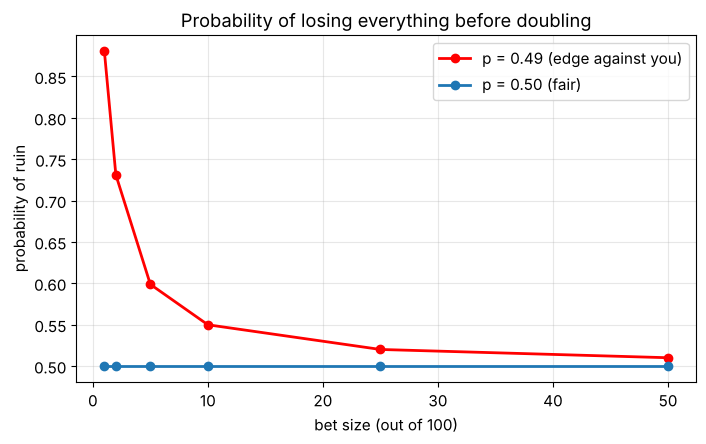

In [13]:
p_bad, x0, a = 0.49, 50, 100
print("bet size   effective x   effective a   P(ruin)")
for b in [1, 2, 5, 10, 25, 50]:
    print(f"   {b:3d}        {x0 // b:5d}        {a // b:5d}       {ruin_prob(x0 // b, a // b, p_bad):.4f}")

bets = [1, 2, 5, 10, 25, 50]
plt.plot(bets, [ruin_prob(x0 // b, a // b, p_bad) for b in bets], "o-", color="red", lw=2, label="p = 0.49 (edge against you)")
plt.plot(bets, [ruin_prob(x0 // b, a // b, 0.50) for b in bets], "o-", lw=2, label="p = 0.50 (fair)")
plt.title("Probability of losing everything before doubling")
plt.xlabel("bet size (out of 100)"); plt.ylabel("probability of ruin"); plt.legend(); plt.show()

Betting 1 at a time gives a 88.1% probability of losing everything before doubling, and betting 50 at
once lowers it to 51.0%, almost the fair-game number. With a fair game the bet size does not change
anything. This explains something about my own experience with trading: a small negative edge, like
the one commissions create, almost guarantees a loss when it is repeated many times. The formula is not
a way to beat a losing game, since the expected wealth is negative with any bet size. What it shows is
that with a negative edge, many small trades are the worst option.

## Wrapping up Module 3

This module moved from describing models to estimating them with real data. The main result is the
difference between the mean and the risk. The mean return of the IPC would need hundreds of years of
data to be known within 2%, while the volatility is estimated well in a few months, and it is the
volatility, not the return, that has a memory that can be modeled and forecast. The AR(1) forecast of
volatility beats the simple alternatives, although it goes back to normal too fast after a crisis like
2008.

The discrete models also worked with real data. A calibrated binomial tree for the dollar matches the
lognormal, and the gambler's ruin formula is close to which barrier the IPC touched first. In both
cases the history agrees with the model as much as it can, because once the overlap is removed there
are only about 20 independent years or 15 independent episodes behind it. The same care applies to the
autocorrelations: with a band that allows the volatility to change, only the one-day reversal of the SPY
and a very small one-day memory of the IPC remain. The bet sizing result is the only one without market
data, and it explains why many small trades with a negative edge are the worst way to invest.

The next step is Module 4, where the steps of the tree become infinitely small and the random walk
becomes Brownian motion.